# 05 · Show notes: map-reduce with a local LLM, checked by rules

**Process.** A show-notes draft has three to five title suggestions, YouTube tags, a description
(followed by the chapter list) and a short summary. It is produced with a local LLM (Qwen3.5-9B
GGUF on `llama.cpp`):

1. **Map:** the transcript is cut into chunks of at most 1,600 words (along chapter boundaries when
   possible), and each chunk is summarised.
2. **Reduce:** the chunk summaries and the chapter titles go into one prompt that writes the draft
   as JSON. A **grammar** forces the output to be valid JSON with the right fields.
3. **Validate** (`validate.py`): normalise what can be repaired (lengths, duplicates, `#` on tags),
   and reject what cannot (too few titles or tags, empty fields). A rejected draft is retried.

There is no ground truth for show notes. The evaluation therefore has two parts: rule checks,
measured here on every stored draft, and the owner's blind review (report).

| | |
|---|---|
| Report | §3 *Show-Notes Generation*; §4 *Show Notes* |
| Code | `backend/app/shownotes/` (`chunking.py`, `prompts.py`, `pipeline.py`, `validate.py`) |
| Decisions | 0011 (show notes with a local LLM), 0016 (9B on the RTX 5070) |
| In-house LLM on the same task | `experiments/m16-own-llm/07_evaluation.ipynb` (show-notes gate: 86 % valid) |

Only counts and lengths are printed, never the drafted text (0026 §3).

In [1]:
import json
import re

from yts_nb import *  # first: puts backend/ on sys.path
from app.chapters.text import clean_title
from app.schemas.show_notes import MAX_DESCRIPTION_CHARS, MAX_SUMMARY_CHARS, MAX_TAGS, MAX_TAGS_CHARS, MAX_TITLES, tags_length
from app.shownotes import chunking, validate

print({"MIN_TITLES": validate.MIN_TITLES, "MAX_TITLES": MAX_TITLES, "MIN_TAGS": validate.MIN_TAGS, "MAX_TAGS": MAX_TAGS,
       "MAX_TAGS_CHARS": MAX_TAGS_CHARS, "MAX_LLM_DESCRIPTION_CHARS": validate.MAX_LLM_DESCRIPTION_CHARS,
       "MAX_DESCRIPTION_CHARS": MAX_DESCRIPTION_CHARS, "MAX_SUMMARY_CHARS": MAX_SUMMARY_CHARS})

{'MIN_TITLES': 3, 'MAX_TITLES': 5, 'MIN_TAGS': 5, 'MAX_TAGS': 15, 'MAX_TAGS_CHARS': 500, 'MAX_LLM_DESCRIPTION_CHARS': 1500, 'MAX_DESCRIPTION_CHARS': 5000, 'MAX_SUMMARY_CHARS': 600}


## 1. The stored drafts

In [2]:
drafts = await sql("""
    select d.upload_id, d.title_suggestions, d.description, d.tags, d.summary, d.language, d.llm_model_used
    from show_notes_drafts d order by d.upload_id
""")
drafts.groupby(["llm_model_used", "language"]).size().to_frame("drafts")

drafts
llm_model_used                 language        
Qwen3.5-9B-Q4_K_M+shownotes-v1 en             2
                               es            60
yts-own-110m-dpo+shownotes-v1  es             1

## 2. Rule checks on every draft

Each stored draft is serialised back to JSON and passed through the same `parse_draft` that
accepts model output. A stored draft must pass, and normalising it again must not change it. The
draft must also respect YouTube's limits once the chapter list is added (description ≤ 5,000
characters, tags ≤ 500 characters in total).

In [3]:
SENT = re.compile(r"[.!?…](?=\s|$)")
rows = []
for d in drafts.itertuples():
    raw = json.dumps({"title_suggestions": d.title_suggestions, "description": d.description.split("\n\n")[0],
                      "tags": list(d.tags), "summary": d.summary})
    try:
        parsed = validate.parse_draft(raw)
        ok, stable = True, (parsed.title_suggestions == d.title_suggestions and parsed.tags == list(d.tags)
                            and parsed.summary == d.summary)
    except validate.DraftInvalid as e:
        ok, stable = False, False
    rows.append({
        "upload_id": d.upload_id, "model": d.llm_model_used.split("+")[0], "valid": ok, "stable": stable,
        "titles": len(d.title_suggestions), "tags": len(d.tags), "tags_chars": tags_length(list(d.tags)),
        "description_chars": len(d.description),
        "description_words": len(d.description.split("\n\n")[0].split()),
        "has_chapter_block": "\n\n" in d.description,
        "summary_sentences": len(SENT.findall(d.summary)), "summary_chars": len(d.summary),
    })
checks = pd.DataFrame(rows)
print(f"valid: {checks.valid.sum()} / {len(checks)}; unchanged by re-normalisation: {checks.stable.sum()} / {len(checks)}")
print(f"within YouTube limits: description {(checks.description_chars <= MAX_DESCRIPTION_CHARS).mean():.0%}, "
      f"tags {(checks.tags_chars <= MAX_TAGS_CHARS).mean():.0%}; with chapter block: {checks.has_chapter_block.mean():.0%}")
checks.drop(columns=["upload_id", "model", "valid", "stable", "has_chapter_block"]).describe().T[["mean", "min", "50%", "max"]]

valid: 63 / 63; unchanged by re-normalisation: 63 / 63
within YouTube limits: description 100%, tags 100%; with chapter block: 100%


,mean,min,50%,max
titles,5.000,5.0,5.0,5.0
tags,14.873,8.0,15.0,15.0
tags_chars,156.683,60.0,149.0,258.0
description_chars,760.857,579.0,760.0,909.0
description_words,92.810,66.0,91.0,120.0
summary_sentences,3.000,0.0,3.0,4.0
summary_chars,396.635,121.0,407.0,523.0


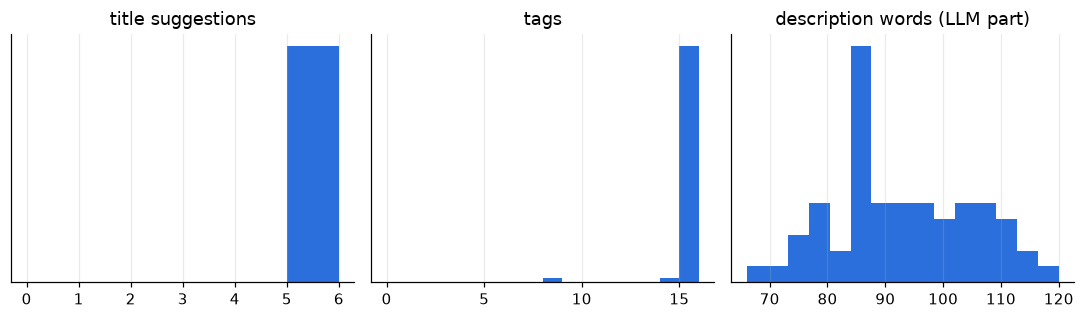

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, col, title in zip(axes, ["titles", "tags", "description_words"],
                          ["title suggestions", "tags", "description words (LLM part)"]):
    ax.hist(checks[col], bins=15 if col == "description_words" else range(0, checks[col].max() + 2), color=COLORS[0])
    ax.set(title=title, yticks=[])
plt.tight_layout()
plt.show()

## 3. A known weakness: titles that repeat chapter titles

The review noted that some title suggestions repeated a chapter title, because the reduce prompt
receives the chapter titles. This cell measures how often that happens: a suggestion counts as a
repeat when its normalised text equals a chapter title of the same episode.

In [5]:
chapters = await sql("select upload_id, title from chapters")
norm = lambda s: re.sub(r"[^\w]+", " ", clean_title(s).lower()).strip()  # noqa: E731
ch_titles = chapters.groupby("upload_id").title.apply(lambda t: {norm(x) for x in t}).to_dict()
rep = [(d.upload_id, sum(norm(t) in ch_titles.get(d.upload_id, set()) for t in d.title_suggestions), len(d.title_suggestions))
       for d in drafts.itertuples()]
rep = pd.DataFrame(rep, columns=["upload_id", "repeats", "titles"])
print(f"title suggestions identical to a chapter title: {rep.repeats.sum()} of {rep.titles.sum()} "
      f"({rep.repeats.sum() / rep.titles.sum():.1%}); drafts with at least one: {(rep.repeats > 0).sum()} of {len(rep)}")

title suggestions identical to a chapter title: 65 of 315 (20.6%); drafts with at least one: 33 of 63


## 4. Map-reduce size and time

In [6]:
segs = await sql("""
    select s.upload_id, s.start_seconds, s.end_seconds, s.text from transcript_segments s order by s.upload_id, s.segment_index
""")
chs = await sql("select upload_id, start_seconds, title from chapters order by upload_id, order_index")
n_chunks = []
for uid, g in segs.groupby("upload_id"):
    seg_objs = [chunking.Seg(r.start_seconds, r.end_seconds, r.text) for r in g.itertuples()]
    marks = [chunking.ChapterMark(r.start_seconds, r.title) for r in chs[chs.upload_id == uid].itertuples()]
    chunks = chunking.make_chunks(seg_objs, marks)
    n_chunks.append({"upload_id": uid, "words": sum(chunking.word_count(s.text) for s in seg_objs), "map_chunks": len(chunks)})
n_chunks = pd.DataFrame(n_chunks)
print(f"map chunks per episode: median {n_chunks.map_chunks.median():.0f}, range {n_chunks.map_chunks.min()}–{n_chunks.map_chunks.max()}")

jobs = await sql("""
    select extract(epoch from completed_at - started_at)::float as seconds, started_at
    from jobs where tool_type = 'shownotes' and status = 'succeeded' and started_at is not null
""")
q = jobs.seconds.quantile([0.1, 0.5, 0.9])
print(f"show-notes jobs on the RTX 5070: {len(jobs)}; median {q[0.5]:.0f} s, 10th–90th percentile {q[0.1]:.0f}–{q[0.9]:.0f} s, "
      f"max {jobs.seconds.max():.0f} s")

map chunks per episode: median 6, range 4–9
show-notes jobs on the RTX 5070: 64; median 58 s, 10th–90th percentile 36–128 s, max 783 s


Job times include waits for the shared GPU lock while another episode's jobs run, so the tail is
long. The report's 52–110 s comes from the five-episode benchmark in notebook 08.

## Summary

- Every stored draft passes the validation rules and is stable under re-normalisation, and all
  fit YouTube's limits with the chapter list added. With grammar-constrained JSON, the checks that
  can still fail are the content rules.
- The repeat of chapter titles noted in the review is measurable and stays a known limitation.
- Quality beyond the rules was judged in a blind review (report, *Show Notes*). The in-house LLM
  reached 86 % valid drafts on the same rules and failed its gate (M16 notebook 07).